In [1]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("../data/seg_train_test/seg_train")

rows = []
for class_dir in sorted(DATA_DIR.iterdir()):
    if class_dir.is_dir():
        for img in class_dir.glob("*"):
            rows.append({"path": str(img), "label": class_dir.name})

df = pd.DataFrame(rows)
print(df.shape)
df.head()

(17034, 2)


,path,label
0,../data/seg_train_test/seg_train/buildings/230...,buildings
1,../data/seg_train_test/seg_train/buildings/329...,buildings
2,../data/seg_train_test/seg_train/buildings/113...,buildings
3,../data/seg_train_test/seg_train/buildings/116...,buildings
4,../data/seg_train_test/seg_train/buildings/111...,buildings


label
mountain     3037
glacier      2957
street       2883
sea          2784
forest       2745
buildings    2628
Name: count, dtype: int64


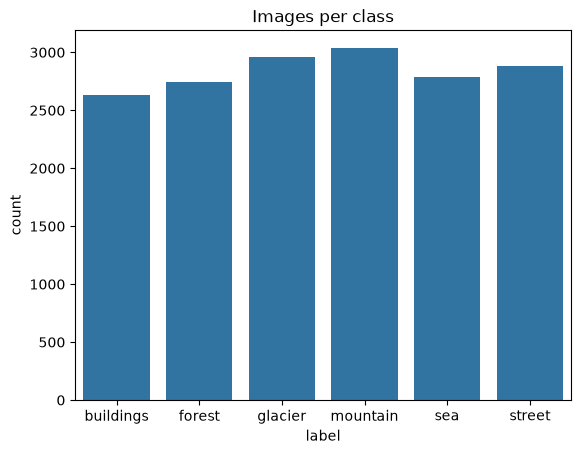

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

print(df["label"].value_counts())

sns.countplot(data=df, x="label")
plt.title("Images per class")
plt.show()

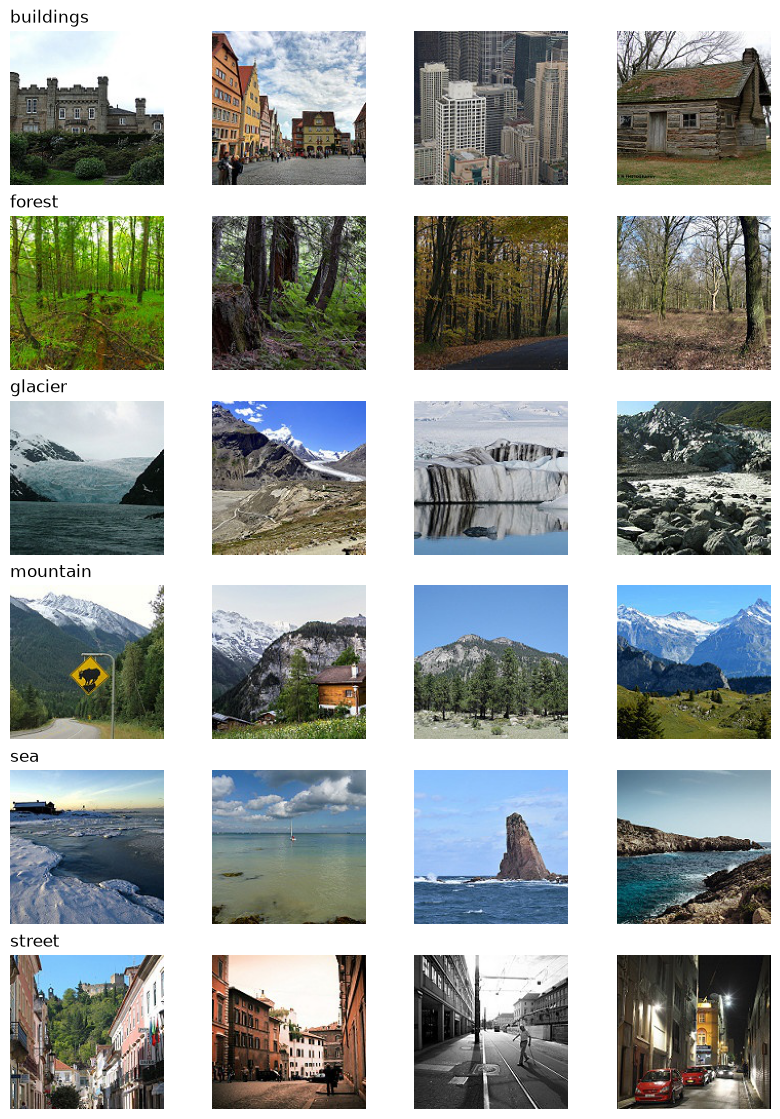

In [6]:
from PIL import Image

classes = sorted(df["label"].unique())
fig, axes = plt.subplots(len(classes), 4, figsize=(10, 14))

for i, c in enumerate(classes):
    samples = df[df["label"] == c].sample(4, random_state=1)
    for j, path in enumerate(samples["path"]):
        axes[i, j].imshow(Image.open(path))
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(c, loc="left")
plt.show()

In [7]:
from collections import Counter

sizes, formats, bad = Counter(), Counter(), []

for p in df["path"]:
    try:
        with Image.open(p) as im:
            sizes[im.size] += 1
            formats[im.format] += 1
            im.verify()
    except Exception:
        bad.append(p)

print("Top sizes:", sizes.most_common(5))
print("Formats:", formats)
print("Bad files:", bad)

Top sizes: [((150, 150), 16979), ((150, 113), 7), ((150, 135), 3), ((150, 111), 3), ((150, 136), 2)]
Formats: Counter({'JPEG': 17034})
Bad files: []


In [8]:
import hashlib

def file_hash(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

df["hash"] = df["path"].apply(file_hash)
print("Duplicates:", df["hash"].duplicated().sum())

Duplicates: 18


In [9]:
df = df.drop_duplicates("hash").drop(columns="hash").reset_index(drop=True)
print(df.shape)

(17016, 2)


In [10]:
from sklearn.model_selection import train_test_split

# First cut: 70% train, 30% temporary
df_train, df_temp = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42,
)

# Second cut: split the 30% in half -> 15% val, 15% test
df_val, df_test = train_test_split(
    df_temp,
    test_size=0.50,
    stratify=df_temp["label"],
    random_state=42,
)

print(len(df_train), len(df_val), len(df_test))
print(df_train["label"].value_counts(normalize=True).round(3))

11911 2552 2553
label
mountain     0.178
glacier      0.174
street       0.169
sea          0.163
forest       0.161
buildings    0.154
Name: proportion, dtype: float64


In [11]:
df_train.to_csv("../data/train.csv", index=False)
df_val.to_csv("../data/val.csv", index=False)
df_test.to_csv("../data/test.csv", index=False)